# Detecting Fake Websites with Machine Learning
### Group No: 15
#### F21DL Data Mining and Machine Learning, Group Coursework
---

| Name | Student number | Contribution |
|---|---|---|
| Arafa Mehar | H | R1, R2 |
| Syed Umraaz | H | R1, R2 |
| Sakib Dalal | H | R1, R3 |
| Eric | H | R1, R4 |
| Rishab Dhinesh | H | R1, R4 |

---

- Datasets:
    - PhiUSIIL Phishing URL Dataset, UCI Machine Learning Repository (ID 967), CC BY 4.0
    - Image CNN Dataset

---

## Notebook Index
All of the code for requirements R1 to R4 is in this notebook.
1. The questions and the hypotheses (R1)
2. Loading and cleaning the data (R2)
3. Looking at the data with graphs (R2)
4. Choosing the features (R2)
5. Clustering (R2)
6. The classical models (R3)
7. The decision tree (R3)
8. The neural networks (R4)
9. The final comparison and the conclusion
   
---


## Imports and settings

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
os.environ["TRANSFORMERS_VERBOSITY"] = "error"

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

TEST_SIZE = 0.30
CLASS_NAMES = ["Phishing", "Legitimate"]

SIMILARITY_FEATURES = ["URLSimilarityIndex", "URLTitleMatchScore", "DomainTitleMatchScore"]

Matplotlib is building the font cache; this may take a moment.


---
# Step 01: *Questions and the hypotheses (R1)*
---

---
# Step 02: *Loading and cleaning the data (R2)*

The dataset is one CSV file. The file is in the `Datasets` folder, which is one level above this notebook, so the path starts with `..`.

---

In [2]:
DATASET_FILE = "PhiUSIIL_Phishing_URL_Dataset.csv"
DATA_PATH = os.path.join("..", "Datasets", DATASET_FILE)

print("File found:", os.path.exists(DATA_PATH))

File found: True


In [3]:
df = pd.read_csv(DATA_PATH)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 235795
Columns: 56


In [4]:
df.head()

,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,Title,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,3,1,0,0,0.0,18,0.581,0,0.0,0,0,0,1,0.032,1,558,9381,1,à¸‚à¹ˆà¸²à¸§à¸ªà¸” à¸‚à¹ˆà¸²à¸§à¸§à¸±à¸™à¸™à¸µ...,0.000000,0.000000,0,1,1,0,0,0,0,1,0,0,1,1,0,1,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,2,1,0,0,0.0,9,0.391,0,0.0,0,0,0,2,0.087,1,618,9381,1,johannes gutenberg-universitÃ¤t mainz,55.555556,55.555556,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,2,2,0,0,0.0,15,0.517,0,0.0,0,0,0,2,0.069,1,467,682,1,voice fm southampton,46.666667,46.666667,0,1,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,0.057606,3,1,0,0,0.0,13,0.500,0,0.0,0,0,0,1,0.038,1,6356,26824,1,home page: seminars in fetal and neonatal medi...,0.000000,0.000000,0,1,1,0,0,0,1,12,0,1,1,1,0,0,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,0.059441,3,1,0,0,0.0,20,0.606,0,0.0,0,0,0,1,0.030,1,6089,28404,1,fundaciÃ³n rewilding argentina,100.000000,100.000000,0,1,1,1,1,1,0,2,0,1,1,1,0,1,1,0,1,244,15,34,72,1,85,1


The columns we care about are these.

- `URL` is the address of the website. It is text.
- `label` is the answer. It is 1 for a real website and 0 for a phishing website.
- The rest are numbers about the URL and about the page, like `URLLength`, `IsHTTPS`, `LineOfCode`, `NoOfImage` and `NoOfExternalRef`.

---
# Step 03: *Looking at the data with graphs (R2)*

Before we change anything, we look at the column types, the summary numbers, and how many rows are in each class.

---

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  str    
 1   URL                         235795 non-null  str    
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  str    
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  str    
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12  NoOfSubDomain               235795 non-null  int64  
 13  HasObfuscation           

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
URLLength,235795.0,34.573095,41.314153,13.000000,23.000000,27.000000,34.000000,6.097000e+03
DomainLength,235795.0,21.470396,9.150793,4.000000,16.000000,20.000000,24.000000,1.100000e+02
IsDomainIP,235795.0,0.002706,0.051946,0.000000,0.000000,0.000000,0.000000,1.000000e+00
URLSimilarityIndex,235795.0,78.430778,28.976055,0.155574,57.024793,100.000000,100.000000,1.000000e+02
CharContinuationRate,235795.0,0.845508,0.216632,0.000000,0.680000,1.000000,1.000000,1.000000e+00
TLDLegitimateProb,235795.0,0.260423,0.251628,0.000000,0.005977,0.079963,0.522907,5.229071e-01
URLCharProb,235795.0,0.055747,0.010587,0.001083,0.050747,0.057970,0.062875,9.082366e-02
TLDLength,235795.0,2.764456,0.599739,2.000000,2.000000,3.000000,3.000000,1.300000e+01
NoOfSubDomain,235795.0,1.164758,0.600969,0.000000,1.000000,1.000000,1.000000,1.000000e+01
HasObfuscation,235795.0,0.002057,0.045306,0.000000,0.000000,0.000000,0.000000,1.000000e+00


In [8]:
df["label"].value_counts()

label
1    134850
0    100945
Name: count, dtype: int64

There are `134,850` real websites and `100,945` phishing websites.

So a model that always says "legitimate" would already be right about 57 percent of the time. That is our base line. A model has to do much better than 57 percent to be worth anything.

## Step 3.1: Cleaning the data (R2)

We made five changes.

- We remove duplicate URLs. The same page can appear more than once. If one copy is in the training data and the other is in the test data, the model looks better than it really is.
- We look for missing values.
- We remove any column that has only one value, because it cannot help.
- We remove the identifier and text columns. The models need numbers, so a column of addresses cannot help them directly. We keep a copy of the addresses, because the model in Step 13.2 counts things inside them.
- We turn the domain ending (`com`, `org`, ...) into a number, because the ending is a real signal and the models need numbers.

In [9]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate URLs:", df["URL"].duplicated().sum())

df = df.drop_duplicates(subset="URL").reset_index(drop=True)
print("Rows left:", len(df))

Duplicate rows: 0
Duplicate URLs: 425
Rows left: 235370


In [10]:
print("Missing values:", df.isna().sum().sum())

Missing values: 0


In [11]:
single_value_columns = []
for column in df.columns:
    if df[column].nunique() == 1:
        single_value_columns.append(column)

print("Columns with only one value:", single_value_columns)

df = df.drop(columns=single_value_columns)
print("Shape:", df.shape)

Columns with only one value: []
Shape: (235370, 56)


In [12]:
# we keep the addresses in their own Series, because the model reads them
url_list = df["URL"].copy()

df = df.drop(columns=["URL", "FILENAME", "Domain", "Title"])
print("Shape of the number table:", df.shape)

Shape of the number table: (235370, 52)


In [13]:
from sklearn.preprocessing import LabelEncoder

tld_encoder = LabelEncoder()
df["TLDCode"] = tld_encoder.fit_transform(df["TLD"])
df = df.drop(columns=["TLD"])

print("Shape:", df.shape)

Shape: (235370, 52)


In [15]:
# Checking the final datatypes in each column
for name, values in df.items():
    print(name, "->", values.dtype)

URLLength -> int64
DomainLength -> int64
IsDomainIP -> int64
URLSimilarityIndex -> float64
CharContinuationRate -> float64
TLDLegitimateProb -> float64
URLCharProb -> float64
TLDLength -> int64
NoOfSubDomain -> int64
HasObfuscation -> int64
NoOfObfuscatedChar -> int64
ObfuscationRatio -> float64
NoOfLettersInURL -> int64
LetterRatioInURL -> float64
NoOfDegitsInURL -> int64
DegitRatioInURL -> float64
NoOfEqualsInURL -> int64
NoOfQMarkInURL -> int64
NoOfAmpersandInURL -> int64
NoOfOtherSpecialCharsInURL -> int64
SpacialCharRatioInURL -> float64
IsHTTPS -> int64
LineOfCode -> int64
LargestLineLength -> int64
HasTitle -> int64
DomainTitleMatchScore -> float64
URLTitleMatchScore -> float64
HasFavicon -> int64
Robots -> int64
IsResponsive -> int64
NoOfURLRedirect -> int64
NoOfSelfRedirect -> int64
HasDescription -> int64
NoOfPopup -> int64
NoOfiFrame -> int64
HasExternalFormSubmit -> int64
HasSocialNet -> int64
HasSubmitButton -> int64
HasHiddenFields -> int64
HasPasswordField -> int64
Bank 

## Step 3.2 - Looking at the data (R2)

Here we will make three graphs to see how the two classes differ.

#### How long is the URL's

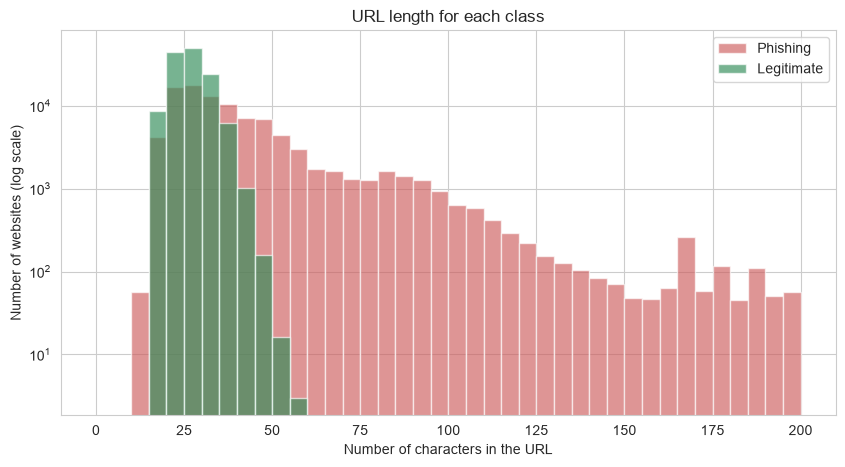

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,100520.0,45.70,61.25,13.0,26.0,34.0,48.0,6097.0
1,134850.0,26.23,4.82,15.0,23.0,26.0,29.0,57.0


In [16]:
bins = np.arange(0, 205, 5)

plt.figure(figsize=(10, 5))
plt.hist(df.loc[df["label"] == 0, "URLLength"], bins=bins, log=True,
         color="indianred", alpha=0.65, label="Phishing")
plt.hist(df.loc[df["label"] == 1, "URLLength"], bins=bins, log=True,
         color="seagreen", alpha=0.65, label="Legitimate")
plt.title("URL length for each class")
plt.xlabel("Number of characters in the URL")
plt.ylabel("Number of websites (log scale)")
plt.legend()
plt.show()

df.groupby("label")["URLLength"].describe().round(2)

- The real websites are short. Half of them are 26 characters or less, and the longest one has only 57 characters.
- The phishing URLs are longer. Half of them are 34 characters or more, and the longest one has 6097 characters. A phishing URL carries extra words and extra parameters, because it tries to copy the name of the brand it is pretending to be.
- The y axis is a log scale, because there are very few very long URLs.

#### Flags in URL and on the page
These four columns are only 0 or 1, so we plot the share of each class where the flag is 1.

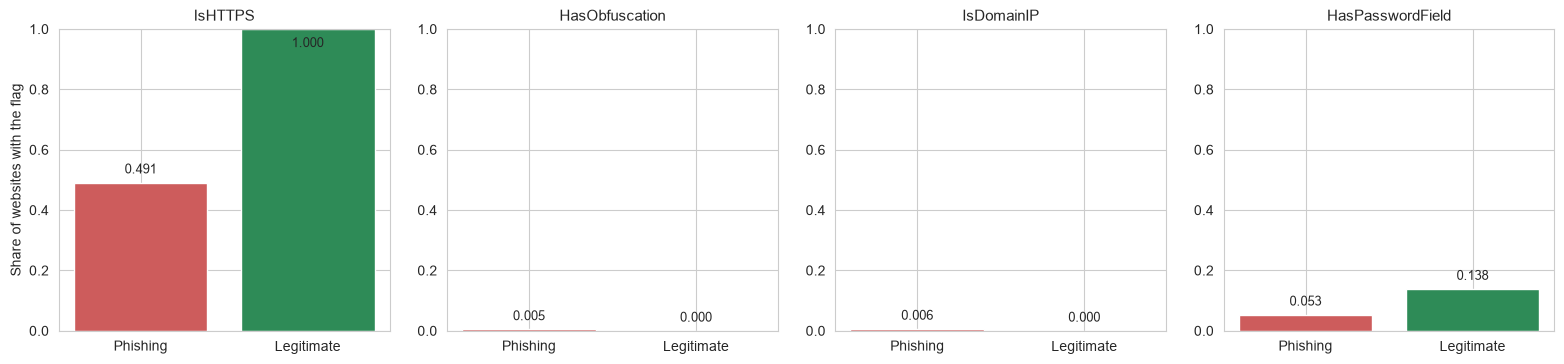

In [17]:
flag_columns = ["IsHTTPS", "HasObfuscation", "IsDomainIP", "HasPasswordField"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].set_ylabel("Share of websites with the flag")

for number in range(4):
    axis = axes[number]
    column = flag_columns[number]

    rates = df.groupby("label")[column].mean()
    axis.bar(CLASS_NAMES, rates.values, color=["indianred", "seagreen"])
    axis.set_title(column, fontsize=11)
    axis.set_ylim(0, 1)
    for position, value in enumerate(rates.values):
        label_height = min(value + 0.03, 0.94)
        axis.text(position, label_height, f"{value:.3f}", ha="center", fontsize=9)

plt.tight_layout(pad=2)
plt.show()

Three things came out of this graph, and two of them surprised us.

- IsHTTPS helps, but only one way round. Every real website uses HTTPS, and only half of the phishing websites do. So no padlock is a warning sign, but a padlock proves nothing, because a certificate is free.
- HasPasswordField is more common on the real websites (0.138) than on the fake ones (0.053). We expected the opposite. We think the phishing pages send the password to another server, so the page has a form but no password box of its own.
- HasObfuscation and IsDomainIP are rare. They appear on 0.005 and 0.006 of the phishing websites, and on none of the real ones. The bars are almost flat, so read the numbers above them. When one of these appears, the website is almost certainly phishing.

---
# Step 04: *Choosing the features (R2)*
---

---
# Step 05: *Clustering (R2)*
---

---
# Step 06: *Classical Models (R3)*
---

---
# Step 07: *Decision Tree (R3)*
---

---
# Step 08: *Neural Networks (R4)*
---

---
# Step 09: *Final Comparison and the Conclusion (R4)*
---